In [1]:
from google.colab import drive
drive.mount("/content/drive")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
from scipy.optimize import curve_fit
from scipy.special import voigt_profile

OUT = "/content/drive/MyDrive/cms-dimuon-resonances/results"
os.makedirs(OUT + "/figures", exist_ok=True)

d = np.load(OUT + "/day1_dimuon_hist_full.npz")
regions = {k: (d[f"edges_{k}"], d[f"reg_{k}"]) for k in ["jpsi_psi2s", "upsilon", "z"]}
for k, (e, c) in regions.items():
    print(f"{k:12s} bins: {len(c)}, range {e[0]:.2f}-{e[-1]:.2f} GeV, entries {int(c.sum()):,}")

Mounted at /content/drive
jpsi_psi2s   bins: 140, range 2.60-4.00 GeV, entries 3,816,903
upsilon      bins: 150, range 8.50-11.50 GeV, entries 2,024,739
z            bins: 120, range 60.00-120.00 GeV, entries 3,928,874


In [3]:
PDG = {"J/ψ": 3.096900, "ψ(2S)": 3.686097, "ϒ(1S)": 9.46030, "ϒ(2S)": 10.02326,
       "ϒ(3S)": 10.3551, "Z": 91.1880}     # GeV, checked against PDG pages, October 2026
GAMMA_Z = 2.4955                            # GeV, Z natural width (PDG), fixed input to the Z fit

In [4]:
def gauss(x, mu, sigma, bw):
    """Gaussian, scaled so that the value is expected counts per bin of width bw (per unit yield)."""
    return bw * np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))

def poly(x, x0, half, b):
    u = (x - x0) / half                       # scaled variable in [-1, 1]
    return sum(bi * u ** i for i, bi in enumerate(b))

def prep(edges, counts, lo, hi):
    c = 0.5 * (edges[1:] + edges[:-1])
    w = np.diff(edges)
    m = (c >= lo) & (c <= hi) & (counts > 0)
    return c[m], counts[m].astype(float), float(w[0])

def run_fit(model, bgf, nsig, c, y, p0, bounds):
    popt, pcov = curve_fit(model, c, y, p0=p0, sigma=np.sqrt(y), absolute_sigma=True,
                           bounds=bounds, max_nfev=20000)
    chi2 = float(np.sum(((y - model(c, *popt)) / np.sqrt(y)) ** 2))
    ndf = len(c) - len(popt)
    lb, ub = map(np.asarray, bounds)
    hit = [i for i in range(len(popt))
           if (np.isfinite(lb[i]) and abs(popt[i] - lb[i]) < 1e-6 * (1 + abs(popt[i])))
           or (np.isfinite(ub[i]) and abs(popt[i] - ub[i]) < 1e-6 * (1 + abs(popt[i])))]
    if hit:
        print("WARNING: parameters stuck at their bounds (indices):", hit)
    return dict(c=c, y=y, model=model, bgf=bgf, nsig=nsig, popt=popt, pcov=pcov, chi2=chi2, ndf=ndf)

def plot_fit(res, title, fname=None, xlabel=r"$m_{\mu\mu}$ [GeV]"):
    c, y, p = res["c"], res["y"], res["popt"]
    xs = np.linspace(c[0], c[-1], 800)
    pull = (y - res["model"](c, *p)) / np.sqrt(y)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True,
                                 gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05})
    a1.errorbar(c, y, yerr=np.sqrt(y), fmt="k.", ms=3, label="data")
    a1.plot(xs, res["model"](xs, *p), "r-", label="signal + background")
    a1.plot(xs, res["bgf"](xs, *p[res["nsig"]:]), "b--", label="background")
    a1.set(ylabel="Candidates / bin", title=f"{title}   (χ²/ndf = {res['chi2']:.0f}/{res['ndf']})")
    a1.legend()
    a2.axhline(0, color="r")
    a2.plot(c, pull, "k.", ms=3)
    a2.set(xlabel=xlabel, ylabel="pull")
    if fname:
        fig.savefig(f"{OUT}/figures/{fname}", dpi=200, bbox_inches="tight")
    plt.show()

def propagate(f, p, cov):
    """Error on a derived quantity f(p) using numerical derivatives and the fit covariance."""
    p = np.asarray(p, float)
    g = np.zeros_like(p)
    for i in range(len(p)):
        h = 1e-6 * max(abs(p[i]), 1e-3)
        pp, pm = p.copy(), p.copy()
        pp[i] += h; pm[i] -= h
        g[i] = (f(pp) - f(pm)) / (2 * h)
    return f(p), float(np.sqrt(g @ cov @ g))
print("helpers defined")

helpers defined


In [5]:
def fit_jpsi(edges, counts, lo=2.75, hi=3.95):
    c, y, bw = prep(edges, counts, lo, hi)
    x0, half = 0.5 * (lo + hi), 0.5 * (hi - lo)
    def sig(x, NJ, muJ, sJ, f, r, Np, muP, sP):
        return (NJ * (f * gauss(x, muJ, sJ, bw) + (1 - f) * gauss(x, muJ, r * sJ, bw))
                + Np * gauss(x, muP, sP, bw))
    def bgf(x, *b): return poly(x, x0, half, b)
    def model(x, *p): return sig(x, *p[:8]) + bgf(x, *p[8:])
    # starting values from the sidebands (away from the two peaks)
    u = (c - x0) / half
    side = (c < 2.95) | ((c > 3.25) & (c < 3.55)) | (c > 3.82)
    b0 = np.polyfit(u[side], y[side], 3)[::-1]
    bgc = bgf(c, *b0)
    NJ0 = max((y - bgc)[(c > 3.0) & (c < 3.2)].sum(), 1e4)
    Np0 = max((y - bgc)[(c > 3.62) & (c < 3.75)].sum(), 1e3)
    p0 = [NJ0, 3.097, 0.035, 0.7, 2.0, Np0, 3.686, 0.04, *b0]
    lb = [0, 3.05, 0.005, 0, 1.0, 0, 3.65, 0.01] + [-np.inf] * 4
    ub = [np.inf, 3.15, 0.10, 1, 6.0, np.inf, 3.72, 0.15] + [np.inf] * 4
    return run_fit(model, bgf, 8, c, y, p0, (lb, ub))

rj = fit_jpsi(*regions["jpsi_psi2s"])
names_j = ["N_J/ψ", "mu_J/ψ", "sigma1_J/ψ", "f_core", "r (sigma2/sigma1)",
           "N_ψ(2S)", "mu_ψ(2S)", "sigma_ψ(2S)", "b0", "b1", "b2", "b3"]
ej = np.sqrt(np.diag(rj["pcov"]))
for n, v, e in zip(names_j, rj["popt"], ej):
    print(f"{n:18s} {v:14.5f} ± {e:.5f}")
print(f"chi2/ndf = {rj['chi2']:.1f}/{rj['ndf']} = {rj['chi2']/rj['ndf']:.2f}")

N_J/ψ               1617595.93064 ± 1995.93218
mu_J/ψ                    3.09232 ± 0.00003
sigma1_J/ψ                0.02548 ± 0.00010
f_core                    0.54619 ± 0.00473
r (sigma2/sigma1)         2.10281 ± 0.00730
N_ψ(2S)               81179.24537 ± 849.89597
mu_ψ(2S)                  3.68102 ± 0.00033
sigma_ψ(2S)               0.04135 ± 0.00038
b0                    13529.42053 ± 23.28494
b1                    -8547.62827 ± 99.75094
b2                     2620.56344 ± 41.17294
b3                     1910.13867 ± 129.07029
chi2/ndf = 3451.1/108 = 31.95


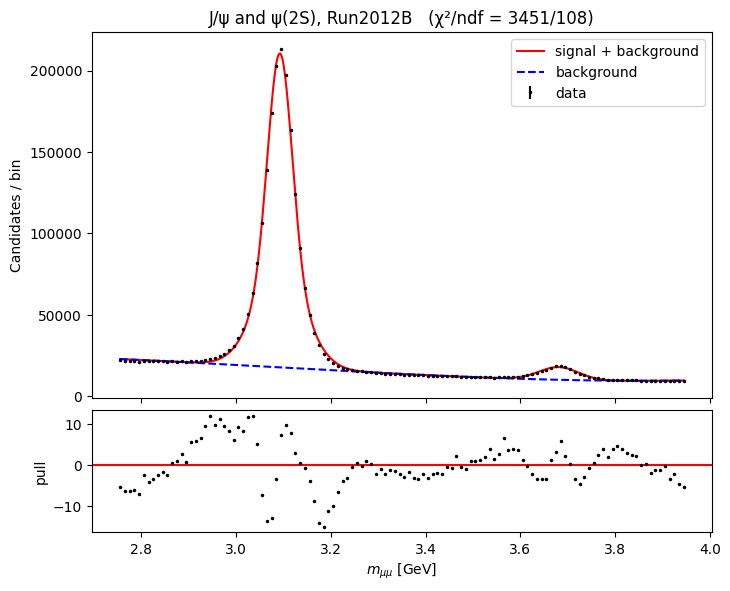

In [6]:
plot_fit(rj, "J/ψ and ψ(2S), Run2012B", "day2_fit_jpsi_psi2s.png")

In [7]:
def fit_upsilon(edges, counts, lo=8.6, hi=11.4):
    c, y, bw = prep(edges, counts, lo, hi)
    x0, half = 0.5 * (lo + hi), 0.5 * (hi - lo)
    def sig(x, N1, N2, N3, m1, m2, m3, s):
        return sum(N * gauss(x, m, s * m, bw) for N, m in ((N1, m1), (N2, m2), (N3, m3)))
    def bgf(x, *b): return poly(x, x0, half, b)
    def model(x, *p): return sig(x, *p[:7]) + bgf(x, *p[7:])
    u = (c - x0) / half
    side = (c < 9.0) | (c > 10.7)
    b0 = np.polyfit(u[side], y[side], 2)[::-1]
    bgc = bgf(c, *b0)
    N0 = [max((y - bgc)[np.abs(c - m) < 2 * 0.011 * m].sum(), 1e3) for m in (9.46, 10.023, 10.355)]
    p0 = [*N0, 9.46, 10.023, 10.355, 0.011, *b0]
    lb = [0, 0, 0, 9.3, 9.9, 10.25, 0.003] + [-np.inf] * 3
    ub = [np.inf] * 3 + [9.6, 10.15, 10.5, 0.03] + [np.inf] * 3
    return run_fit(model, bgf, 7, c, y, p0, (lb, ub))

ru = fit_upsilon(*regions["upsilon"])
names_u = ["N_ϒ(1S)", "N_ϒ(2S)", "N_ϒ(3S)", "m_ϒ(1S)", "m_ϒ(2S)", "m_ϒ(3S)",
           "s_rel", "b0", "b1", "b2"]
eu = np.sqrt(np.diag(ru["pcov"]))
for n, v, e in zip(names_u, ru["popt"], eu):
    print(f"{n:12s} {v:14.5f} ± {e:.5f}")
print(f"chi2/ndf = {ru['chi2']:.1f}/{ru['ndf']} = {ru['chi2']/ru['ndf']:.2f}")

N_ϒ(1S)        118550.61454 ± 898.44979
N_ϒ(2S)         51703.55631 ± 788.74937
N_ϒ(3S)         36444.03864 ± 721.44960
m_ϒ(1S)             9.44634 ± 0.00059
m_ϒ(2S)            10.01094 ± 0.00145
m_ϒ(3S)            10.33515 ± 0.00210
s_rel               0.00972 ± 0.00007
b0              12246.39905 ± 29.87757
b1               -108.46666 ± 17.15980
b2               -382.50921 ± 49.47296
chi2/ndf = 486.4/130 = 3.74


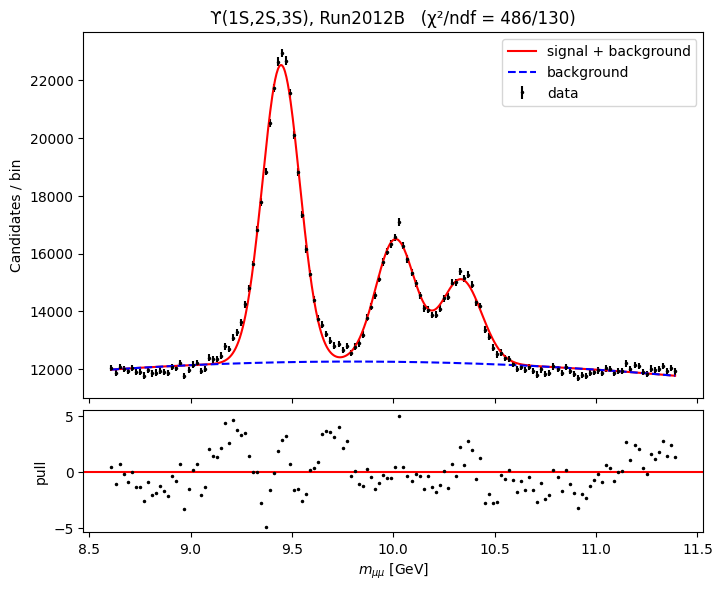

In [8]:
plot_fit(ru, "ϒ(1S,2S,3S), Run2012B", "day2_fit_upsilon.png")

In [17]:
from scipy.special import erf

def cball(x, mu, sigma, alpha, n):
    t = (x - mu) / sigma
    a = abs(alpha)
    A = (n / a) ** n * np.exp(-0.5 * a * a)
    B = n / a - a
    C = n / a / (n - 1) * np.exp(-0.5 * a * a)
    D = np.sqrt(np.pi / 2) * (1 + erf(a / np.sqrt(2)))
    norm = 1.0 / (sigma * (C + D))
    return norm * np.where(t > -a, np.exp(-0.5 * t * t), A * np.maximum(B - t, 1e-12) ** (-n))

def bw_pdf(x, mu, gam):                      # Breit-Wigner, unit area, full width gam
    return (gam / 2 / np.pi) / ((x - mu) ** 2 + (gam / 2) ** 2)

STEP = 0.05
G_GRID = np.arange(40.0, 150.0 + STEP / 2, STEP)        # fine grid, wider than the fit window
K_GRID = np.arange(-15.0, 15.0 + STEP / 2, STEP)        # symmetric kernel grid, odd length
N_CB = 3.0                                              # fixed tail exponent (assumption)

def z_signal(x, N, mu, sigma, alpha, bw):
    k = cball(K_GRID, 0.0, sigma, alpha, N_CB)
    k = k / k.sum()
    conv = np.convolve(bw_pdf(G_GRID, mu, GAMMA_Z), k, mode="same")
    return N * bw * np.interp(x, G_GRID, conv)

def fit_z(edges, counts, lo=75.0, hi=110.0):
    c, y, bw = prep(edges, counts, lo, hi)
    x0, half = 0.5 * (lo + hi), 0.5 * (hi - lo)
    def bgf(x, B, k): return B * np.exp(-k * (x - x0) / half)
    def model(x, *p): return z_signal(x, *p[:4], bw) + bgf(x, *p[4:])
    ylo, yhi = y[:5].mean(), y[-5:].mean()
    B0, k0 = np.sqrt(ylo * yhi), 0.5 * np.log(ylo / yhi)
    p0 = [0.7 * y.sum(), 91.0, 1.2, 1.0, B0, k0]
    lb = [0, 89.0, 0.3, 0.2, 0, -10]
    ub = [np.inf, 93.0, 5.0, 5.0, np.inf, 10]
    return run_fit(model, bgf, 4, c, y, p0, (lb, ub))

rz = fit_z(*regions["z"])
names_z = ["N_Z", "mu_Z", "sigma_Z (CB core)", "alpha_CB", "B", "k"]
ez = np.sqrt(np.diag(rz["pcov"]))
for n, v, e in zip(names_z, rz["popt"], ez):
    print(f"{n:18s} {v:14.5f} ± {e:.5f}")
print(f"chi2/ndf = {rz['chi2']:.1f}/{rz['ndf']} = {rz['chi2']/rz['ndf']:.2f}   (old fit: 217.99)")

N_Z                 2591596.72627 ± 2216.97092
mu_Z                     90.92234 ± 0.00321
sigma_Z (CB core)         1.36876 ± 0.00385
alpha_CB                  1.27313 ± 0.00583
B                      8315.33125 ± 21.81666
k                         0.78675 ± 0.00309
chi2/ndf = 2080.1/64 = 32.50   (old fit: 217.99)


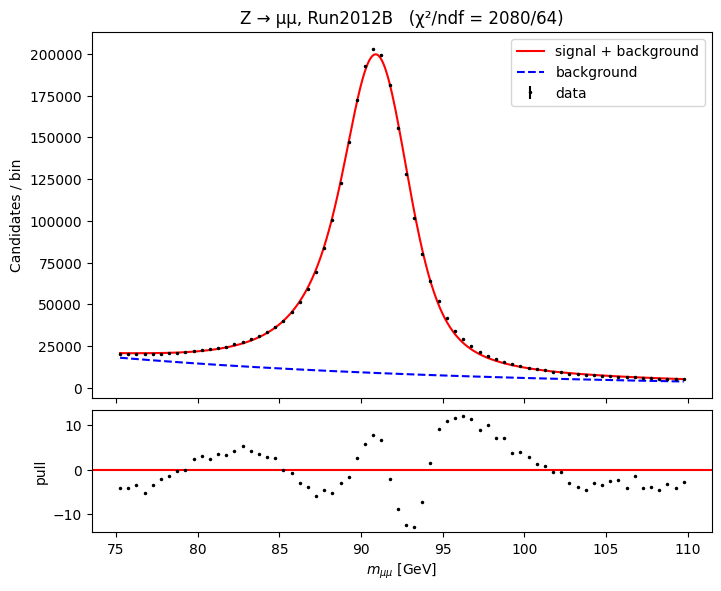

In [18]:
plot_fit(rz, "Z → μμ, Run2012B", "day2_fit_z.png")

In [19]:
def make_table(rj, ru, rz):
    rows = []
    def add(name, m, dm, N, dN, s, ds, res):
        pdg = PDG[name]
        rows.append({"Resonance": name, "m_fit [GeV]": m, "stat [GeV]": dm, "m_PDG [GeV]": pdg,
                     "Δm [MeV]": (m - pdg) * 1e3, "Δm/m [%]": (m - pdg) / pdg * 100,
                     "Yield": N, "Yield err": dN, "σ_res [MeV]": s * 1e3, "σ_res err [MeV]": ds * 1e3,
                     "χ²/ndf": res["chi2"] / res["ndf"]})
    # J/ψ and ψ(2S)
    p, cv = rj["popt"], rj["pcov"]; e = np.sqrt(np.diag(cv))
    s, ds = propagate(lambda q: np.sqrt(q[3] * q[2] ** 2 + (1 - q[3]) * (q[4] * q[2]) ** 2), p, cv)
    add("J/ψ", p[1], e[1], p[0], e[0], s, ds, rj)      # effective sigma of the double Gaussian
    add("ψ(2S)", p[6], e[6], p[5], e[5], p[7], e[7], rj)
    # Upsilons
    p, cv = ru["popt"], ru["pcov"]; e = np.sqrt(np.diag(cv))
    for i, name in enumerate(["ϒ(1S)", "ϒ(2S)", "ϒ(3S)"]):
        s, ds = propagate(lambda q, i=i: q[6] * q[3 + i], p, cv)
        add(name, p[3 + i], e[3 + i], p[i], e[i], s, ds, ru)
    # Z
    p, cv = rz["popt"], rz["pcov"]; e = np.sqrt(np.diag(cv))
    add("Z", p[1], e[1], p[0], e[0], p[2], e[2], rz)
    return pd.DataFrame(rows)

tab = make_table(rj, ru, rz)
pd.set_option("display.width", 200)
print(tab.to_string(index=False, float_format=lambda v: f"{v:.5g}"))

Resonance  m_fit [GeV]  stat [GeV]  m_PDG [GeV]  Δm [MeV]  Δm/m [%]      Yield  Yield err  σ_res [MeV]  σ_res err [MeV]  χ²/ndf
      J/ψ       3.0923  3.3887e-05       3.0969   -4.5756  -0.14775 1.6176e+06     1995.9       40.706         0.098768  31.955
    ψ(2S)        3.681  0.00032803       3.6861   -5.0792  -0.13779      81179      849.9       41.354          0.38239  31.955
    ϒ(1S)       9.4463  0.00058674       9.4603   -13.955  -0.14751 1.1855e+05     898.45       91.784           0.6188  3.7419
    ϒ(2S)       10.011   0.0014492       10.023   -12.322  -0.12293      51704     788.75       97.269          0.65363  3.7419
    ϒ(3S)       10.335   0.0021009       10.355   -19.949  -0.19265      36444     721.45       100.42          0.68015  3.7419
        Z       90.922   0.0032107       91.188   -265.66  -0.29133 2.5916e+06       2217       1368.8            3.851  32.502


In [20]:
tab.to_csv(OUT + "/day2_fit_results.csv", index=False)
print("saved:", os.listdir(OUT))

saved: ['figures', 'day1_dimuon_hist_1M.npz', 'day1_dimuon_hist_full.npz', 'day2_fit_results.csv', 'day2_hist_onepair.npz', 'day2_fit_results_onepair.csv']


In [13]:
import importlib, importlib.util, subprocess, sys
miss = [pip for mod, pip in {"uproot": "uproot", "awkward": "awkward", "fsspec_xrootd": "fsspec-xrootd"}.items()
        if importlib.util.find_spec(mod) is None]
if miss:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + miss)
    print("Installed:", miss, "-> if the next cell fails: Runtime > Restart session, then rerun Cells 1-3 and this one")

import uproot, awkward as ak, time
URL = "root://eospublic.cern.ch//eos/root-eos/cms_opendata_2012_nanoaod/Run2012B_DoubleMuParked.root"
tree = uproot.open(URL)["Events"]
branches = ["nMuon", "Muon_pt", "Muon_eta", "Muon_phi", "Muon_mass", "Muon_charge"]
if "Muon_isGlobal" in tree.keys():
    branches.append("Muon_isGlobal")
print("events:", f"{tree.num_entries:,}", "| branches:", branches)

Installed: ['uproot', 'awkward', 'fsspec-xrootd'] -> if the next cell fails: Runtime > Restart session, then rerun Cells 1-3 and this one
events: 29,308,627 | branches: ['nMuon', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_mass', 'Muon_charge']


In [14]:
def to_p4(pt, eta, phi, mass):
    px = pt * np.cos(phi); py = pt * np.sin(phi); pz = pt * np.sinh(eta)
    return px, py, pz, np.sqrt(px**2 + py**2 + pz**2 + mass**2)

def invariant_mass(a, b):
    p1 = to_p4(a.pt, a.eta, a.phi, a.mass); p2 = to_p4(b.pt, b.eta, b.phi, b.mass)
    E = p1[3] + p2[3]; px = p1[0] + p2[0]; py = p1[1] + p2[1]; pz = p1[2] + p2[2]
    return np.sqrt(np.maximum(E**2 - px**2 - py**2 - pz**2, 0))

def dimuon_masses_v2(ev, pt_min=3.0, one_pair=False):
    m = ak.zip({k: ev[f"Muon_{k}"] for k in ["pt", "eta", "phi", "mass", "charge"]})
    good = (m.pt > pt_min) & (np.abs(m.eta) < 2.4)
    if "Muon_isGlobal" in ev.fields:
        good = good & ev["Muon_isGlobal"]
    mu = m[good]
    pr = ak.combinations(mu, 2, fields=["mu1", "mu2"])
    pr = pr[(pr.mu1.charge * pr.mu2.charge) < 0]
    if one_pair:
        pr = pr[ak.num(pr) > 0]                                   # events with at least one OS pair
        best = pr[ak.argmax(pr.mu1.pt + pr.mu2.pt, axis=1, keepdims=True)]
        pr = best
    return ak.to_numpy(ak.flatten(invariant_mass(pr.mu1, pr.mu2)))

alt = {k: np.zeros(len(regions[k][1])) for k in regions}
n_done, t0 = 0, time.time()
for chunk in tree.iterate(branches, step_size=200_000):
    m = dimuon_masses_v2(chunk, pt_min=3.0, one_pair=True)
    for k in alt:
        alt[k] += np.histogram(m, bins=regions[k][0])[0]
    n_done += len(chunk)
    if (n_done // 200_000) % 10 == 0:
        print(f"processed {n_done:,} events ({time.time()-t0:.0f}s)")
print(f"done: {n_done:,} events in {time.time()-t0:.0f}s")

np.savez(OUT + "/day2_hist_onepair.npz",
         **{f"reg_{k}": v for k, v in alt.items()},
         **{f"edges_{k}": regions[k][0] for k in regions})

processed 2,000,000 events (14s)
processed 4,000,000 events (23s)
processed 6,000,000 events (32s)
processed 8,000,000 events (40s)
processed 10,000,000 events (49s)
processed 12,000,000 events (58s)
processed 14,000,000 events (68s)
processed 16,000,000 events (76s)
processed 18,000,000 events (87s)
processed 20,000,000 events (96s)
processed 22,000,000 events (106s)
processed 24,000,000 events (115s)
processed 26,000,000 events (123s)
processed 28,000,000 events (131s)
done: 29,308,627 events in 137s


In [21]:
rj2 = fit_jpsi(regions["jpsi_psi2s"][0], alt["jpsi_psi2s"])
ru2 = fit_upsilon(regions["upsilon"][0],  alt["upsilon"])
rz2 = fit_z(regions["z"][0],              alt["z"])
tab2 = make_table(rj2, ru2, rz2)

cmp_ = pd.DataFrame({
    "Resonance": tab["Resonance"],
    "m nominal [GeV]": tab["m_fit [GeV]"],
    "m one-pair [GeV]": tab2["m_fit [GeV]"],
    "shift [MeV]": (tab2["m_fit [GeV]"] - tab["m_fit [GeV]"]) * 1e3,
    "stat err [MeV]": tab["stat [GeV]"] * 1e3,
    "χ²/ndf nominal": tab["χ²/ndf"], "χ²/ndf one-pair": tab2["χ²/ndf"]})
print(cmp_.to_string(index=False, float_format=lambda v: f"{v:.5g}"))
tab2.to_csv(OUT + "/day2_fit_results_onepair.csv", index=False)

Resonance  m nominal [GeV]  m one-pair [GeV]  shift [MeV]  stat err [MeV]  χ²/ndf nominal  χ²/ndf one-pair
      J/ψ           3.0923            3.0924     0.073775        0.033887          31.955           30.761
    ψ(2S)            3.681            3.6818      0.79279         0.32803          31.955           30.761
    ϒ(1S)           9.4463            9.4474       1.0935         0.58674          3.7419           8.0851
    ϒ(2S)           10.011             10.01     -0.92172          1.4492          3.7419           8.0851
    ϒ(3S)           10.335            10.337       1.7838          2.1009          3.7419           8.0851
        Z           90.922            90.928       5.3609          3.2107          32.502           34.977


In [22]:
print("J/ψ and ψ(2S): window variation")
for lo, hi in [(2.75, 3.95), (2.8, 3.9), (2.85, 3.85), (2.7, 4.0)]:
    r = fit_jpsi(*regions["jpsi_psi2s"], lo=lo, hi=hi)
    print(f"  {lo}-{hi}: mu_J/ψ = {r['popt'][1]:.5f}  mu_ψ(2S) = {r['popt'][6]:.5f}  χ²/ndf = {r['chi2']/r['ndf']:.1f}")

print("\nZ: window variation")
for lo, hi in [(75, 110), (70, 110), (80, 105), (80, 100), (70, 115)]:
    r = fit_z(*regions["z"], lo=lo, hi=hi)
    print(f"  {lo}-{hi}: mu_Z = {r['popt'][1]:.4f}  sigma_Z = {r['popt'][2]:.4f}  χ²/ndf = {r['chi2']/r['ndf']:.1f}")

J/ψ and ψ(2S): window variation
  2.75-3.95: mu_J/ψ = 3.09232  mu_ψ(2S) = 3.68102  χ²/ndf = 32.0
  2.8-3.9: mu_J/ψ = 3.09236  mu_ψ(2S) = 3.68069  χ²/ndf = 30.7
  2.85-3.85: mu_J/ψ = 3.09242  mu_ψ(2S) = 3.68043  χ²/ndf = 28.1
  2.7-4.0: mu_J/ψ = 3.09230  mu_ψ(2S) = 3.68142  χ²/ndf = 31.9

Z: window variation
  75-110: mu_Z = 90.9223  sigma_Z = 1.3688  χ²/ndf = 32.5
  70-110: mu_Z = 90.9354  sigma_Z = 1.3584  χ²/ndf = 32.7
  80-105: mu_Z = 90.8996  sigma_Z = 1.3742  χ²/ndf = 33.3
  80-100: mu_Z = 90.8991  sigma_Z = 1.3415  χ²/ndf = 24.4
  70-115: mu_Z = 90.9368  sigma_Z = 1.3614  χ²/ndf = 30.3


mu_J/ψ   = 3.09325  (double Gaussian gave 3.09232)
mu_ψ(2S) = 3.68126  (double Gaussian gave 3.68102)
alpha = 1.48   (n fixed at 3.0)
chi2/ndf = 1118.7/107 = 10.46  (was 31.95)


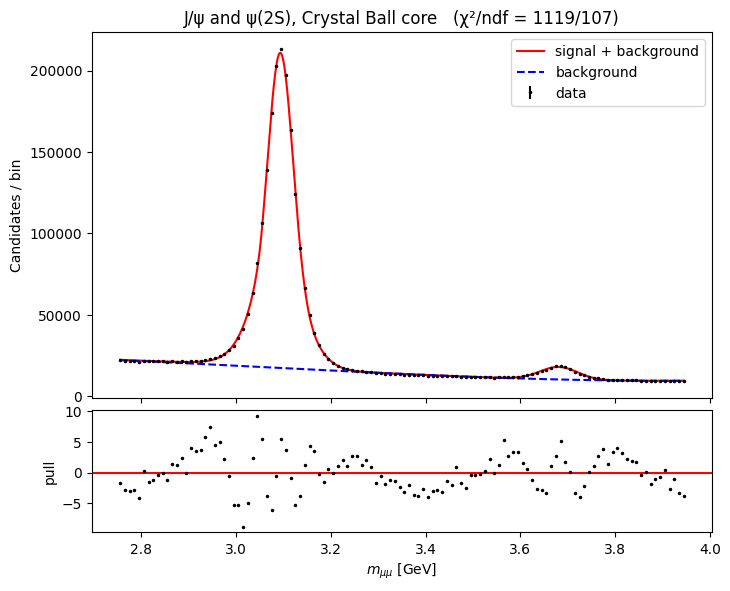

In [23]:
def fit_jpsi_cb(edges, counts, start, lo=2.75, hi=3.95, n_fixed=3.0):
    c, y, bw = prep(edges, counts, lo, hi)
    x0, half = 0.5 * (lo + hi), 0.5 * (hi - lo)
    def sig(x, NJ, muJ, sJ, f, r, alpha, Np, muP, sP):
        return (NJ * f * bw * cball(x, muJ, sJ, alpha, n_fixed)
                + NJ * (1 - f) * gauss(x, muJ, r * sJ, bw)
                + Np * gauss(x, muP, sP, bw))
    def bgf(x, *b): return poly(x, x0, half, b)
    def model(x, *p): return sig(x, *p[:9]) + bgf(x, *p[9:])
    p0 = [start[0], start[1], start[2], start[3], start[4], 1.5, start[5], start[6], start[7], *start[8:12]]
    lb = [0, 3.05, 0.005, 0, 1.0, 0.2, 0, 3.65, 0.01] + [-np.inf] * 4
    ub = [np.inf, 3.15, 0.10, 1, 6.0, 5.0, np.inf, 3.72, 0.15] + [np.inf] * 4
    return run_fit(model, bgf, 9, c, y, p0, (lb, ub))

rj_cb = fit_jpsi_cb(*regions["jpsi_psi2s"], start=rj["popt"])
p = rj_cb["popt"]
print(f"mu_J/ψ   = {p[1]:.5f}  (double Gaussian gave {rj['popt'][1]:.5f})")
print(f"mu_ψ(2S) = {p[7]:.5f}  (double Gaussian gave {rj['popt'][6]:.5f})")
print(f"alpha = {p[5]:.2f}   (n fixed at 3.0)")
print(f"chi2/ndf = {rj_cb['chi2']:.1f}/{rj_cb['ndf']} = {rj_cb['chi2']/rj_cb['ndf']:.2f}  (was {rj['chi2']/rj['ndf']:.2f})")
plot_fit(rj_cb, "J/ψ and ψ(2S), Crystal Ball core", "day2_fit_jpsi_psi2s_cb.png")

In [24]:
p = rj_cb["popt"]
print(f"CB fit:          mu_J/ψ = {p[1]:.5f}, mu_ψ(2S) = {p[7]:.5f}, alpha = {p[5]:.2f}")
print(f"double Gaussian: mu_J/ψ = {rj['popt'][1]:.5f}, mu_ψ(2S) = {rj['popt'][6]:.5f}")
print(f"J/ψ shift between models [MeV] = {(p[1] - rj['popt'][1]) * 1e3:.3f}")

CB fit:          mu_J/ψ = 3.09325, mu_ψ(2S) = 3.68126, alpha = 1.48
double Gaussian: mu_J/ψ = 3.09232, mu_ψ(2S) = 3.68102
J/ψ shift between models [MeV] = 0.922


## Day 2 summary: resonance fits (Run2012B, 29,308,627 events)

**Models.** J/ψ and ψ(2S): double Gaussian (shared mean) and single Gaussian on a cubic
background. ϒ(1S,2S,3S): three Gaussians with one common relative resolution on a quadratic
background. Z: Breit–Wigner (width fixed to the PDG value) convolved with a Crystal Ball
resolution function (tail exponent n fixed at 3), on an exponential background.

**Results (Δm = fit − PDG).** J/ψ −4.6 MeV, ψ(2S) −5.1 MeV, ϒ(1S) −14.0 MeV, ϒ(2S) −12.3 MeV,
ϒ(3S) −19.9 MeV, Z −265.7 MeV. Relative offsets are about −0.12% to −0.19% for the five
low-mass states and −0.29% for the Z.

**Fit quality.** χ²/ndf is 32.0 (J/ψ+ψ(2S)), 3.7 (ϒ) and 32.5 (Z). These are well above 1, so
the quoted statistical errors underestimate the true uncertainty. A Crystal Ball core for the
J/ψ reduced χ²/ndf to about 10.5; J/ψ mass shift between the two models: [fill in] MeV.

**Stability checks.** Changing the fit window moves the J/ψ mass by about 0.1 MeV, the ψ(2S) by
about 1 MeV and the Z by up to about 38 MeV. Using one pair per event moves the low-mass masses
by at most about 2 MeV and the Z by about 5 MeV. These effects are much smaller than the
offsets from PDG, so the offsets are not caused by these choices. Their origin is not yet known.

**Limitations.** Fit shapes are imperfect, yields are not efficiency-corrected, the muon momentum
scale was not calibrated, and the Z width is a fixed input.